Biblioteka NetworkX udostępnia cztery podstawowe klasy grafów: `Graph`, `DiGraph`, `MultiGraph` oraz `MultiDiGraph`. Różnią się one tym, czy krawędzie mają kierunek i czy pomiędzy tymi samymi wierzchołkami może występować wiele krawędzi.

In [ ]:
import matplotlib.pyplot as plt
import networkx as nx

print("NetworkX", nx.__version__)

## Dodawanie krawędzi

We wszystkich czterech klasach metoda `add_edge(u, v)` dodaje krawędź pomiędzy wierzchołkami 'u' oraz 'v'. Nie dodajemy osobno wierzchołków, metoda tworzy je za nas. Atrybuty krawędzi (takie jak wagi, etykiety etc.) przekazujemy jako argumenty nazwane, na przykład `weight=3` albo `color="red"`. Wiele krawędzi można dodać za pomocą `add_edges_from()`.

### `Graph`

`Graph` jest grafem nieskierowanym bez krawędzi wielokrotnych. Ponowne dodanie tej samej krawędzi nie tworzy nowej krawędzi, lecz aktualizuje jej słownik atrybutów. Funkcja `add_edge(u, v)` oraz `add_edge(v, u)` będzie miała ten sam efekt.

In [ ]:
graph = nx.Graph() #tworzymy pusty graf nieskierowany
graph.add_edge("A", "B", weight=2) #tworzymy krawędź A--B z wagą 2
graph.add_edge("B", "A", color="turquoise") #dodajemy do krawędzi A-B atrybut
graph.add_edge("A", "C", weight=3, color="blue") #tworzymy krawędź A--C z wagą 3 i kolorem niebieskim

print("Wierzchołki:", list(graph.nodes))
print("Krawędzie:", list(graph.edges(data=True)))
print("Dane A--B:", dict(graph.edges["A", "B"]))
print("Sąsiedzi A z danymi:", dict(graph.adj["A"]))

In [ ]:
for u, v, data in graph.edges(data=True):
    print(f"Krawędź {u}--{v} ma atrybuty: {data}")

In [ ]:
list(graph.edges("A", data=True)) #lista krawędzi wychodzących z A wraz z ich atrybutami. Elementami są trójki zaczynające się zawsze od wierzchołka A.

In [ ]:
#ładniej napisana lista krawędzi wychodzących z A wraz z ich atrybutami)
for _, neighbor, data in graph.edges("A", data=True):
    print(f"Krawędź A--{neighbor} ma atrybuty: {data}")

In [ ]:
#można też tak (graph.adj["A"] jest słownikiem sąsiadów A, a jego wartościami są słowniki atrybutów krawędzi):
for neighbor, data in graph.adj["A"].items(): 
    print(f"Krawędź A--{neighbor} ma atrybuty: {data}")

In [ ]:
for node in graph.nodes:
    print(f"Wierzchołek {node} ma sąsiadów: {list(graph.adj[node])}")

### `DiGraph`

`DiGraph` jest grafem skierowanym bez krawędzi wielokrotnych. Krawędzie `u → v` oraz `v → u` są różne. Ponowne dodanie `u → v` aktualizuje dane istniejącej krawędzi.

In [ ]:
digraph = nx.DiGraph()
digraph.add_edge("A", "B", weight=2)
digraph.add_edge("B", "A", weight=5)
digraph.add_edge("A", "B", color="turquoise")
digraph.add_edge("A", "C", weight=3, color="blue")

print("Wierzchołki:", list(digraph.nodes))
print("Krawędzie:", list(digraph.edges(data=True)))
print("Dane A--B:", dict(digraph.edges["A", "B"]))
print("Następnicy A z danymi", dict(digraph.succ["A"]))
print("Poprzednicy A z danymi", dict(digraph.pred["A"]))

In [ ]:
for _, neighbor, data in digraph.edges("A", data=True):
    print(f"Krawędź A-->{neighbor} ma atrybuty: {data}")

In [ ]:
#to samo za pomocą słownika sąsiadów (następców) w grafie skierowanym:
for successor, data in digraph.succ["A"].items():
    print(f"Krawędź A-->{successor} ma atrybuty: {data}")

### `MultiGraph`

`MultiGraph` jest multigrafem nieskierowanym. Każde wywołanie `add_edge(u, v)` bez podanego klucza tworzy kolejną krawędź i zwraca jej utworzony automatycznie klucz. Podanie istniejącego klucza aktualizuje wskazaną krawędź. Można również używać własnych kluczy, na przykład `key="A1"`.

In [ ]:
multigraph = nx.MultiGraph()
multigraph.add_edge("A", "B", key="AB1", route="lokalna")
multigraph.add_edge("A", "B", key="AB2", route="ekspresowa")
multigraph.add_edge("B", "C", key="BC1", color="turquoise")
keyBC = multigraph.add_edge("B", "C", color="yellow")

print("Nadany klucz:", keyBC)
print("Krawędzie:")
for u, v, key, data in multigraph.edges(keys=True, data=True):
    print(u, v, key, data)

In [ ]:
#Aby dostać dane krawędzi, musimy również podać jej klucz:
print("Dane krawędzi B--C o kluczu BC1:", multigraph.edges["B", "C", "BC1"])

In [ ]:
#krawędzie z A wraz z ich atrybutami i kluczami
for _, neighbor, key, data in multigraph.edges("A", keys=True, data=True):
    print(f"Krawędź A--{neighbor} (klucz: {key}) ma atrybuty: {data}")

In [ ]:
#multigraph.adj["A"] jest słownikiem sąsiadów A, a jego wartościami są słowniki, których kluczami są klucze krawędzi, a wartościami są słowniki atrybutów krawędzi):
multigraph.adj["A"]

In [ ]:
#można też tak wypisać krawędzie z A wraz z ich atrybutami i kluczami: 
for neighbor, edges in multigraph.adj["A"].items():
    for key, data in edges.items():
        print(f"Krawędź A--{neighbor} (klucz: {key}) ma atrybuty: {data}")

### `MultiDiGraph`

`MultiDiGraph` łączy kierunek z możliwością przechowywania krawędzi równoległych. Klucze są lokalne dla uporządkowanej pary końców. Dlatego pierwsza krawędź `A → B` i pierwsza krawędź `B → A` mogą otrzymać ten sam klucz.

In [ ]:
multidigraph = nx.MultiDiGraph()
multidigraph.add_edge("A", "B", key="AB1", route="pierwsza")
multidigraph.add_edge("A", "B", key="AB2", route="druga")
multidigraph.add_edge("B", "A", route="powrotna")

for u, v, key, data in multidigraph.edges(keys=True, data=True):
    print(f'Krawędź {u}-->{v} (klucz: {key}) ma atrybuty: {data}')

In [ ]:
for _, node, key, data in multidigraph.edges("A", keys=True, data=True):
    print(f"Krawędź A-->{node} (klucz: {key}) ma atrybuty: {data}")

In [ ]:
for neighbor, edges in multidigraph.succ["A"].items():
    for key, data in edges.items():
        print(f"Krawędź A-->{neighbor} (klucz: {key}) ma atrybuty: {data}")

### Sam klucz nie wystarcza

Klucz multikrawędzi nie jest globalnym identyfikatorem. Ten sam klucz może pojawić się pomiędzy różnymi parami wierzchołków, a NetworkX nie utrzymuje dodatkowego indeksu `key → końce krawędzi`. Jeżeli znamy tylko klucz, musimy przejrzeć krawędzie.

In [ ]:
roads = nx.MultiGraph()
roads.add_edge("Warszawa", "Łódź", key="A1", length=130)
roads.add_edge("Kraków", "Katowice", key="A1", length=80)

matches = [
    (u, v, key, data)
    for u, v, key, data in roads.edges(keys=True, data=True)
    if key == "A1"
]
matches

## Podstawy wizualizacji

Najprostsza funkcja `nx.draw()` jednocześnie wybiera położenia wierzchołków i rysuje graf za pomocą Matplotlib. Do szybkich eksperymentów wystarczy podać `with_labels=True`.

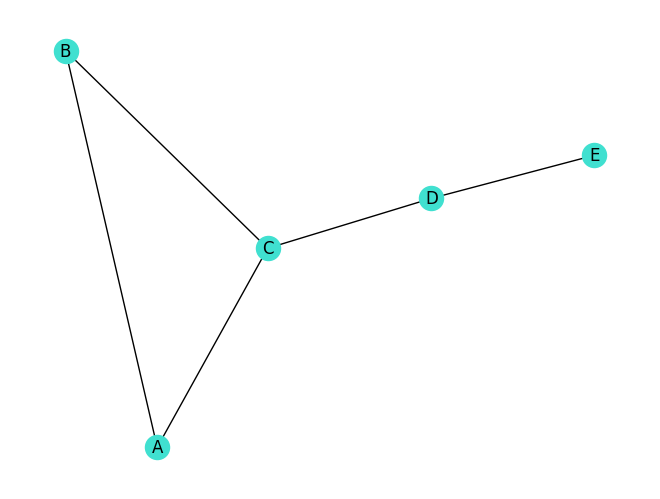

In [181]:
visual_graph = nx.Graph()
visual_graph.add_weighted_edges_from([
    ("A", "B", 2),
    ("A", "C", 4),
    ("B", "C", 1),
    ("C", "D", 3),
    ("D", "E", 2),
])

nx.draw(visual_graph, with_labels=True, node_color="turquoise")
plt.show()

### Pozycje wierzchołków

Funkcja `nx.draw()` może otrzymać w argumencie `pos` słownik, który każdemu wierzchołkowi przypisuje parę współrzędnych `(x, y)`. Dzięki temu sami ustalamy układ grafu, zamiast pozostawiać jego wyznaczenie bibliotece NetworkX. Współrzędne nie oznaczają pikseli ani konkretnych jednostek — ważne jest ich wzajemne położenie: większa wartość `x` przesuwa wierzchołek w prawo, a większa wartość `y` w górę.

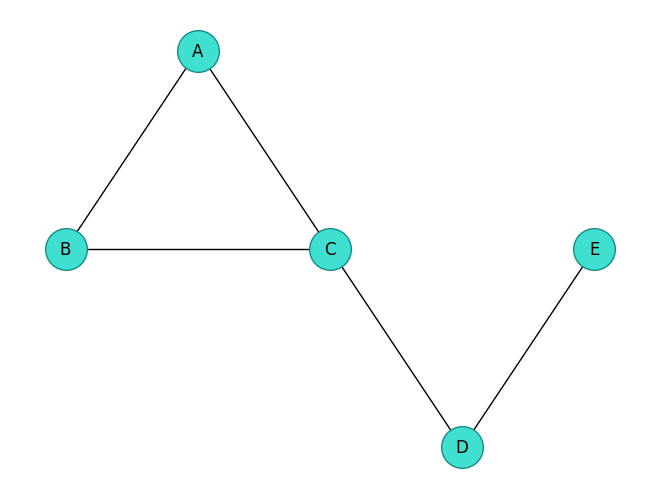

In [182]:
positions = {
    "A": (0, 1),
    "B": (-1, 0),
    "C": (1, 0),
    "D": (2, -1),
    "E": (3, 0),
}

nx.draw(
    visual_graph,
    pos=positions,
    with_labels=True,
    node_color="turquoise",
    edgecolors="#168C88",
    node_size=900,
)
plt.show()

Współrzędnych nie musimy wypisywać sami. Poniższe funkcje tworzą je automatycznie: `spring_layout()` (tego domyślnie używa `nx.draw`), `planar_layout()`, `circular_layout()` i `shell_layout()`. Ustalenie `seed` pozwala odtwarzać ten sam układ losowy.

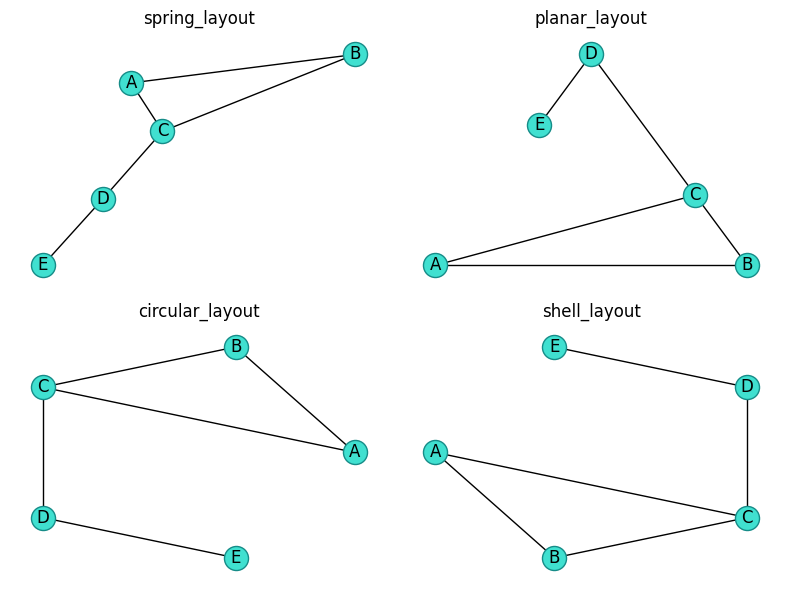

In [183]:
positions = {
    "spring_layout": nx.spring_layout(visual_graph, seed=7),
    "planar_layout": nx.planar_layout(visual_graph),
    "circular_layout": nx.circular_layout(visual_graph),
    "shell_layout": nx.shell_layout(visual_graph),
}

fig, axes = plt.subplots(2, 2, figsize=(8, 6))
for ax, (name, positions) in zip(axes.flat, positions.items()):
    nx.draw(
        visual_graph,
        positions,
        with_labels=True,
        node_color="turquoise",
        edgecolors="#168C88",
        ax=ax,
    )
    ax.set_title(name)
fig.tight_layout()
plt.show()

### Dokładniejsze sterowanie rysunkiem

Funkcja `draw_networkx()` rysuje wierzchołki, krawędzie i etykiety. Gdy potrzebujemy większej kontroli, możemy wywołać osobno `draw_networkx_nodes()`, `draw_networkx_edges()`, `draw_networkx_labels()` oraz `draw_networkx_edge_labels()`.

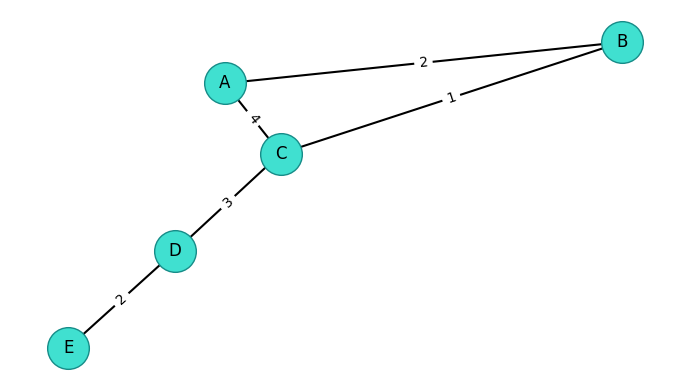

In [184]:
positions = nx.spring_layout(visual_graph, seed=7)
edge_labels = nx.get_edge_attributes(visual_graph, "weight")

fig, ax = plt.subplots(figsize=(7, 4))
nx.draw_networkx_nodes(
    visual_graph, positions, node_color="turquoise",
    edgecolors="#168C88", node_size=900, ax=ax,
)
nx.draw_networkx_edges(visual_graph, positions, width=1.5, ax=ax)
nx.draw_networkx_labels(visual_graph, positions, ax=ax)
nx.draw_networkx_edge_labels(
    visual_graph, positions, edge_labels=edge_labels, ax=ax,
)
ax.set_axis_off()
fig.tight_layout()
plt.show()

Dla grafów skierowanych `draw_networkx_edges()` rysuje groty strzałek. W multigrafach krawędzie równoległe można rozsunąć za pomocą argumentu `connectionstyle`, na przykład `"arc3,rad=0.15"`.